In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
from datetime import datetime

In [2]:
path_fsm=r'data\FSM_all.nc'
path_snow=r'data\snow_metrics.nc'
path_can=r'data\canopysnow_metrics_v7.nc'
ds_terrain = xr.open_dataset(path_fsm,decode_times=True)
ds_snow = xr.open_dataset(path_snow,decode_times=True)
ds_can  = xr.open_dataset(path_can,decode_times=True)

altitudes = ds_terrain['dem'].values.flatten() ## On récupére les données d'altitude
aspect = ds_terrain['aspect'].values.flatten()
forest = ds_terrain["forest"].values.flatten()


primary_mask = (forest >= 0.1)
primary_mask = np.where(primary_mask,1,np.nan)

for s in range(len(ds_snow.season)) :
    curr_season = ds_snow.season[s]

    meb_peak = ds_snow["Peak_SWE"].sel(simulation='MEB_FOR', season = curr_season).values.flatten() 
    fsm_peak = ds_snow["Peak_SWE"].sel(simulation='FSM_FOR', season = curr_season).values.flatten() 
    meb_scd = ds_snow["Snow_duration"].sel(simulation='MEB_FOR', season = curr_season).values.flatten() 
    fsm_scd = ds_snow["Snow_duration"].sel(simulation='FSM_FOR', season = curr_season).values.flatten() 
    
    primary_mask = np.where(meb_peak > 0.1, primary_mask, np.nan)
    primary_mask = np.where(fsm_peak > 0.1, primary_mask, np.nan)
    primary_mask = np.where(meb_scd > 2, primary_mask, np.nan)
    primary_mask = np.where(fsm_scd > 2, primary_mask, np.nan)

## On définit les cadrants
angle = np.array([22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5])  ## ne pas modifier (Angles pour avoir 8 cadrants)
alt = np.arange(1000, 2801, 300)   ## à modifier si on veut aller de 500 à 3500m


<>:100: SyntaxWarning: invalid escape sequence '\D'
<>:100: SyntaxWarning: invalid escape sequence '\D'
C:\Users\mazzottg\AppData\Local\Temp\ipykernel_32028\3617005882.py:100: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel('$\Delta$ Canopy snow losses [mm]',fontsize=12)


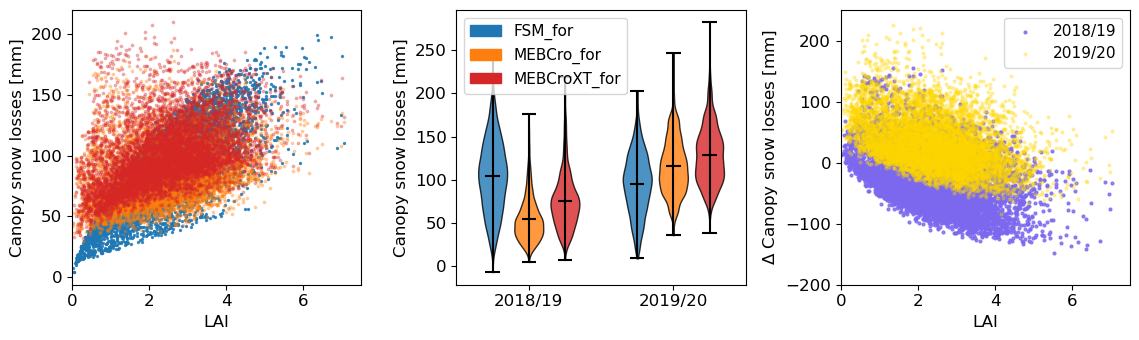

In [6]:
curr_season = '2018/2019'
data_1m = ds_can["Canopy_loss"].sel(simulation='MEB_FOR',season=curr_season).values.flatten()  
data_1f = ds_can["Canopy_loss"].sel(simulation='FSM_FOR',season=curr_season).values.flatten() 
data_1x = ds_can["Canopy_loss"].sel(simulation='MXT_FOR',season=curr_season).values.flatten()  

data_1m = np.where(primary_mask ==1,data_1m,np.nan)  
data_1f = np.where(primary_mask ==1,data_1f,np.nan)  
data_1x = np.where(primary_mask ==1,data_1x,np.nan)  

curr_season = '2019/2020'
data_2m = ds_can["Canopy_loss"].sel(simulation='MEB_FOR',season=curr_season).values.flatten()  
data_2f = ds_can["Canopy_loss"].sel(simulation='FSM_FOR',season=curr_season).values.flatten() 
data_2x = ds_can["Canopy_loss"].sel(simulation='MXT_FOR',season=curr_season).values.flatten()  
data_2m = np.where(primary_mask ==1,data_2m,np.nan)  
data_2f = np.where(primary_mask ==1,data_2f,np.nan)  
data_2x = np.where(primary_mask ==1,data_2x,np.nan)  

#v
data = [data_1f[~np.isnan(data_1f)], data_1m[~np.isnan(data_1m)],  data_1x[~np.isnan(data_1x)], data_2f[~np.isnan(data_2f)], data_2m[~np.isnan(data_2m)], data_2x[~np.isnan(data_2x)]]

# Colors for datasets A and B
colors = ['tab:blue','tab:orange','tab:red']  # blue for A, orange for B
plot_colors = [colors[0], colors[1], colors[2], colors[0], colors[1], colors[2]]

# X positions for the 4 violins
positions = [1, 2, 3, 5, 6, 7]



# --- Create subplots ---
fig, axs = plt.subplots(1,3, figsize=(11.5, 3.5))

ax = axs[1]
parts = ax.violinplot(data, positions=positions, widths=0.8, showmeans=True)

# Color each violin
for i, body in enumerate(parts['bodies']):
    body.set_facecolor(plot_colors[i])
    body.set_edgecolor('black')
    body.set_alpha(0.8)

# Whiskers / extremes
for key in ['cmins', 'cmaxes', 'cmeans', 'cbars']:
    parts[key].set_color("black")

# Ticks and labels
ax.set_xticks([2, 6])
ax.set_xticklabels(['2018/19', '2019/20'])

ax.set_xlim(0, 8)
#ax.set_ylim(0, 300)
ax.set_ylabel('Canopy snow losses [mm]',fontsize=12)


# Legend
import matplotlib.patches as mpatches
legend_patches = [
    mpatches.Patch(color=colors[0], label='FSM_for'),
    mpatches.Patch(color=colors[1], label='MEBCro_for'),
    mpatches.Patch(color=colors[2], label='MEBCroXT_for')
]
ax.legend(handles=legend_patches,fontsize = 11)


ax = axs[0]


can_data = ds_can["Canopy_loss"].sel(simulation='FSM_FOR').mean(dim="season", skipna=True).values.flatten() 
can_data = np.where(primary_mask ==1 ,can_data,np.nan)
ax.scatter( ds_terrain["lai"].values.flatten(),can_data,s=2,alpha=0.8)
can_data = ds_can["Canopy_loss"].sel(simulation='MEB_FOR').mean(dim="season", skipna=True).values.flatten() 
can_data = np.where(primary_mask ==1 ,can_data,np.nan)
ax.scatter( ds_terrain["lai"].values.flatten(),can_data,s=3,alpha=0.3)
can_data = ds_can["Canopy_loss"].sel(simulation='MXT_FOR').mean(dim="season", skipna=True).values.flatten() 
can_data = np.where(primary_mask ==1 ,can_data,np.nan)
ax.scatter( ds_terrain["lai"].values.flatten(),can_data,color=colors[2],s=3,alpha=0.3)
#ax.set_ylim(0, 250)
ax.set_xlim(0, 7.5)
ax.set_xlabel('LAI',fontsize=12)
#ax.set_xticks(np.arange(7))
ax.set_ylabel('Canopy snow losses [mm]',fontsize=12)


ax = axs[2]

curr_season = '2018/2019'
diff_1= ds_can["Canopy_loss"].sel(simulation='MXT_FOR',season=curr_season).values.flatten()  - ds_can["Canopy_loss"].sel(simulation='FSM_FOR',season=curr_season).values.flatten() 
diff_1 = np.where(primary_mask ==1 ,diff_1,np.nan)


curr_season = '2019/2020'
diff_2= ds_can["Canopy_loss"].sel(simulation='MXT_FOR',season=curr_season).values.flatten()  - ds_can["Canopy_loss"].sel(simulation='FSM_FOR',season=curr_season).values.flatten() 
diff_2 = np.where(primary_mask ==1 ,diff_2,np.nan)

ax.scatter( ds_terrain["lai"].values.flatten(),diff_1,s=4,alpha=0.8,c='mediumslateblue',label = '2018/19')
ax.scatter( ds_terrain["lai"].values.flatten(),diff_2,s=4,alpha=0.3,c='gold',label = '2019/20')
ax.set_ylim(-200, 250)
ax.set_xlim(0, 7.5)
ax.set_xlabel('LAI',fontsize=12)
ax.set_ylabel('$\Delta$ Canopy snow losses [mm]',fontsize=12)
ax.legend(fontsize = 11)


for i in np.arange(3) :
    axs[i].tick_params(labelsize=12)
plt.tight_layout()
plt.show()

